# Constrained decipherment with grammatical constraints

## Motivation

The validation of the compositional decipherment (`validation_results.json`) revealed that the glyph→Hebrew mapping is **degenerate**:
- Test 1 (Collapse): DEGENERATE — z=-0.56, 5 degenerate characters (ש z=-5.14, ר z=-3.52)
- Test 2 (N-gram): FAIL — percentile 24% (no better than random)
- Test 3 (Roots): PROMISING — 6 roots, 84× enrichment (unique positive signal)
- Test 4 (Cardinality): MODERATE — 11.3% drop when constraining
- Test 5 (Labels): DIVERGENT — labels worse than main text

**Diagnostic**: The LM score (`w_lm=2.0`) dominates → the EM collapses glyphs onto the most frequent Hebrew characters (shin, resh, vav). The positional score (`w_pos=0.5`) is too weak to diversify.

**Solution**: Three simultaneous corrections:
1. **K_max=7** — penalise excessive cardinality (soft cap)
2. **Entropy bonus** — reward uniform distribution over the alphabet
3. **Grammar anchors** — anchor glyphs with known grammatical roles to compatible Hebrew categories


In [11]:
# ── Cell 1: Imports ──────────────────────────────────────────────────
import re, math, random, io, os, tarfile, json, warnings
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import requests
from scipy import stats as sp_stats
from scipy.spatial.distance import jensenshannon, cosine
from tqdm.notebook import tqdm

warnings.filterwarnings('ignore')

# ── Colours ──
COLOR_ONSET   = '#1565C0'
COLOR_NUCLEAR = '#2E7D32'
COLOR_CODA    = '#F57F17'
COLOR_FREE    = '#757575'

In [12]:
# ── Cell 2: Reused functions from the compositional notebook ────────

def parsear_sta_completo(filepath):
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens


def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras


def construir_matriz_transicion_intrapalabra(palabras):
    all_glyphs = sorted({g for p in palabras for g in p})
    index = {g: i for i, g in enumerate(all_glyphs)}
    n = len(all_glyphs)
    M_raw = np.zeros((n, n))
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            r, c = index[palabra[i]], index[palabra[i + 1]]
            M_raw[r, c] += 1
    row_sums = M_raw.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M_prob = M_raw / row_sums
    return M_raw, M_prob, all_glyphs, index


def segmentar_silabas_tp(palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20):
    all_trans_probs = []
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            if g1 in index_tr and g2 in index_tr:
                all_trans_probs.append(M_prob[index_tr[g1], index_tr[g2]])
    threshold_val = np.percentile(all_trans_probs, threshold_percentile)
    silabas_por_palabra = []
    for palabra in palabras:
        if len(palabra) == 0:
            continue
        syl = [palabra[0]]
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            p = M_prob[index_tr[g1], index_tr[g2]] if (g1 in index_tr and g2 in index_tr) else 0.0
            if p < threshold_val:
                silabas_por_palabra.append(tuple(syl))
                syl = [g2]
            else:
                syl.append(g2)
        if syl:
            silabas_por_palabra.append(tuple(syl))
        silabas_por_palabra.append(None)
    return silabas_por_palabra, all_trans_probs, threshold_val


def catalogar_silabas(silabas_por_palabra):
    syl_freq = Counter()
    syl_per_word = []
    syl_lengths = Counter()
    count_in_word = 0
    for item in silabas_por_palabra:
        if item is None:
            if count_in_word > 0:
                syl_per_word.append(count_in_word)
            count_in_word = 0
        else:
            syl_freq[item] += 1
            syl_lengths[len(item)] += 1
            count_in_word += 1
    if count_in_word > 0:
        syl_per_word.append(count_in_word)
    return syl_freq, syl_per_word, syl_lengths


def clasificar_silabas_posicionalmente(silabas_por_palabra, min_freq=5):
    words_as_syls = []
    current = []
    for item in silabas_por_palabra:
        if item is None:
            if current:
                words_as_syls.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words_as_syls.append(current)
    pos_counts = defaultdict(lambda: {'inicio': 0, 'medio': 0, 'final': 0, 'total': 0})
    for word_syls in words_as_syls:
        n = len(word_syls)
        for i, syl in enumerate(word_syls):
            pos_counts[syl]['total'] += 1
            if n == 1:
                pos_counts[syl]['inicio'] += 1
                pos_counts[syl]['final'] += 1
            elif i == 0:
                pos_counts[syl]['inicio'] += 1
            elif i == n - 1:
                pos_counts[syl]['final'] += 1
            else:
                pos_counts[syl]['medio'] += 1
    clase_silaba = {}
    stats = {}
    for syl, counts in pos_counts.items():
        if counts['total'] < min_freq:
            continue
        total = counts['total']
        r_ini = counts['inicio'] / total
        r_fin = counts['final'] / total
        r_med = counts['medio'] / total
        if r_ini >= 0.60 and r_fin < 0.30:
            clase = 'onset'
        elif r_fin >= 0.60 and r_ini < 0.30:
            clase = 'coda'
        elif r_med >= 0.40:
            clase = 'nuclear'
        else:
            clase = 'free'
        clase_silaba[syl] = clase
        stats[syl] = {'clase': clase, 'inicio': r_ini, 'medio': r_med,
                       'final': r_fin, 'total': total}
    return clase_silaba, stats


def syls_to_words(syls_flat):
    words, current = [], []
    for item in syls_flat:
        if item is None:
            if current:
                words.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words.append(current)
    return words


def clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB):
    glyph_in_class = defaultdict(Counter)
    glyph_position = defaultdict(Counter)
    for word_syls in WORDS_SYL_V:
        for syl in word_syls:
            clase = clase_silaba_v.get(syl, 'free')
            for i, g in enumerate(syl):
                glyph_in_class[g][clase] += 1
                if i == 0:
                    glyph_position[g]['inicio'] += 1
                elif i == len(syl) - 1:
                    glyph_position[g]['fin'] += 1
                else:
                    glyph_position[g]['medio'] += 1
    glyph_role = {}
    glyph_stats = {}
    for g in VOCAB:
        counts = glyph_in_class[g]
        total = sum(counts.values())
        if total < 5:
            glyph_role[g] = '?'
            glyph_stats[g] = {'role': '?', 'total': total, 'pct_nuclear': 0}
            continue
        pct_nuclear = counts.get('nuclear', 0) / total
        pct_onset = counts.get('onset', 0) / total
        pct_coda = counts.get('coda', 0) / total
        glyph_role[g] = 'V' if pct_nuclear > 0.40 else 'C'
        glyph_stats[g] = {
            'role': glyph_role[g], 'total': total,
            'pct_nuclear': pct_nuclear, 'pct_onset': pct_onset,
            'pct_coda': pct_coda, 'pct_free': counts.get('free', 0) / total,
            'pos_inicio': glyph_position[g].get('inicio', 0),
            'pos_medio': glyph_position[g].get('medio', 0),
            'pos_fin': glyph_position[g].get('fin', 0),
        }
    return glyph_role, glyph_stats


# ── Character language model ──

class CharLM:
    def __init__(self, order=3):
        self.order = order
        self.trigram_counts = defaultdict(Counter)
        self.bigram_counts = defaultdict(Counter)
        self.unigram_counts = Counter()
        self.vocab = set()
        self.total = 0
        self._V = 0

    def fit(self, words):
        BOS = '<w>'
        EOS = '</w>'
        for word in words:
            seq = [BOS, BOS] + list(word) + [EOS]
            for c in seq:
                self.vocab.add(c)
                self.unigram_counts[c] += 1
                self.total += 1
            for i in range(len(seq) - 1):
                self.bigram_counts[seq[i]][seq[i+1]] += 1
            for i in range(len(seq) - 2):
                ctx = (seq[i], seq[i+1])
                self.trigram_counts[ctx][seq[i+2]] += 1
        self._V = len(self.vocab)

    def _log_prob_trigram(self, c1, c2, c3):
        ctx = (c1, c2)
        tri_counts = self.trigram_counts[ctx]
        tri_total = sum(tri_counts.values())
        if tri_total > 0:
            tri_seen = len(tri_counts)
            count = tri_counts.get(c3, 0)
            if count > 0:
                prob = count / (tri_total + tri_seen)
                return math.log2(max(prob, 1e-20))
            else:
                lambda_bo = tri_seen / (tri_total + tri_seen)
                bi_counts = self.bigram_counts[c2]
                bi_total = sum(bi_counts.values())
                if bi_total > 0:
                    bi_seen = len(bi_counts)
                    bi_count = bi_counts.get(c3, 0)
                    if bi_count > 0:
                        prob = lambda_bo * bi_count / (bi_total + bi_seen)
                    else:
                        lambda_bo2 = bi_seen / (bi_total + bi_seen)
                        prob = lambda_bo * lambda_bo2 * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                else:
                    prob = lambda_bo * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))
        else:
            bi_counts = self.bigram_counts[c2]
            bi_total = sum(bi_counts.values())
            if bi_total > 0:
                bi_seen = len(bi_counts)
                count = bi_counts.get(c3, 0)
                if count > 0:
                    prob = count / (bi_total + bi_seen)
                else:
                    lambda_bo = bi_seen / (bi_total + bi_seen)
                    prob = lambda_bo * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))
            else:
                prob = (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))

    def log_prob(self, word):
        BOS = '<w>'
        EOS = '</w>'
        seq = [BOS, BOS] + list(word) + [EOS]
        lp = 0.0
        for i in range(2, len(seq)):
            lp += self._log_prob_trigram(seq[i-2], seq[i-1], seq[i])
        return lp

    def perplexity(self, words):
        total_lp = 0.0
        total_n = 0
        for word in words:
            total_lp += self.log_prob(word)
            total_n += len(word) + 1
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)


# ── Glyph → character mapping state ──

class GlyphMappingState:
    def __init__(self, voynich_glyphs, target_chars, glyph_role=None, char_role=None):
        self.voynich_glyphs = list(voynich_glyphs)
        self.target_chars = list(target_chars)
        self.glyph_role = glyph_role or {}
        self.char_role = char_role or {}
        self.mapping = {}

    def set_mapping(self, mapping_dict):
        self.mapping = dict(mapping_dict)

    def propose_change(self, rng, constrained=True):
        new = GlyphMappingState(self.voynich_glyphs, self.target_chars,
                                self.glyph_role, self.char_role)
        new.mapping = dict(self.mapping)
        glyph = rng.choice(self.voynich_glyphs)
        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = [c for c in self.target_chars if self.char_role.get(c) == role]
            if not candidates:
                candidates = self.target_chars
        else:
            candidates = self.target_chars
        new.mapping[glyph] = rng.choice(candidates)
        return new

    def apply_word(self, word_glyphs):
        return [self.mapping.get(g, '?') for g in word_glyphs]

    def apply_corpus(self, words):
        return [self.apply_word(w) for w in words]


# ── Scoring functions base ──

def score_char_lm(mapping, words, char_lm, sample_size=3000):
    rng = np.random.default_rng(0)
    if len(words) > sample_size:
        idx = rng.choice(len(words), size=sample_size, replace=False)
        sample = [words[i] for i in idx]
    else:
        sample = words
    mapped = [mapping.apply_word(w) for w in sample]
    return np.mean([char_lm.log_prob(w) for w in mapped])


def score_positional(mapping, glyph_role, char_role):
    n_ok = sum(1 for g, c in mapping.mapping.items()
               if glyph_role.get(g, '?') == char_role.get(c, '?')
               and glyph_role.get(g) != '?')
    n_total = sum(1 for g in mapping.mapping if glyph_role.get(g) != '?')
    return n_ok / max(n_total, 1)


def score_total_comp(mapping, words, char_lm, glyph_role, char_role,
                     w_lm=2.0, w_pos=0.5):
    s_lm = score_char_lm(mapping, words, char_lm)
    s_pos = score_positional(mapping, glyph_role, char_role)
    return w_lm * s_lm + w_pos * s_pos, {'lm': s_lm, 'pos': s_pos}


def score_total_comp_fast(mapping, words_sample, char_lm, glyph_role, char_role,
                          w_lm=2.0, w_pos=0.5):
    mapped = [mapping.apply_word(w) for w in words_sample]
    s_lm = np.mean([char_lm.log_prob(w) for w in mapped])
    s_pos = score_positional(mapping, glyph_role, char_role)
    return w_lm * s_lm + w_pos * s_pos


# ── Frequency-based initialisation ──

def init_frequency_mapping(palabras, vocab_glyphs, target_chars, target_words,
                           glyph_role, char_role):
    gf = Counter(g for p in palabras for g in p)
    cf = Counter(c for w in target_words for c in w)
    mapping = {}
    for role in ('C', 'V', '?'):
        glyphs_r = sorted([g for g in vocab_glyphs if glyph_role.get(g, '?') == role],
                          key=lambda g: gf[g], reverse=True)
        if role == '?':
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        else:
            chars_r = sorted([c for c in target_chars if char_role.get(c) == role],
                             key=lambda c: cf.get(c, 0), reverse=True)
        if not chars_r:
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        for i, g in enumerate(glyphs_r):
            mapping[g] = chars_r[i % len(chars_r)]
    return mapping


# ── MCMC ──

def mcmc_glyph_refine(initial_state, words, char_lm, glyph_role, char_role,
                      n_iter=15000, T_start=1.0, T_end=0.01, seed=42,
                      sample_size=3000, thin=5,
                      adaptive=True, target_accept=0.35,
                      calibration_samples=300, T_ratio=100,
                      w_lm=2.0, w_pos=0.5,
                      score_fn=None, score_fn_kwargs=None):
    """MCMC Metropolis-Hastings with adaptive annealing.
    If score_fn is provided, uses that function instead of score_total_comp_fast."""
    rng = np.random.default_rng(seed)

    if len(words) > sample_size:
        idx = rng.choice(len(words), size=sample_size, replace=False)
        words_sample = [words[i] for i in idx]
    else:
        words_sample = words

    if score_fn is None:
        def _score(state):
            return score_total_comp_fast(state, words_sample, char_lm,
                                         glyph_role, char_role,
                                         w_lm=w_lm, w_pos=w_pos)
    else:
        _kw = score_fn_kwargs or {}
        def _score(state):
            return score_fn(state, words_sample, char_lm, glyph_role, char_role, **_kw)

    current = initial_state
    current_score = _score(current)

    if adaptive:
        neg_deltas = []
        cal_state = current
        cal_score = current_score
        for _ in range(calibration_samples):
            prop = cal_state.propose_change(rng, constrained=True)
            ps = _score(prop)
            d = ps - cal_score
            if d < 0:
                neg_deltas.append(abs(d))
            cal_state = prop
            cal_score = ps
        if neg_deltas:
            median_neg = float(np.median(neg_deltas))
            T_start = median_neg / (-math.log(target_accept))
            T_end = T_start / T_ratio
            print(f'    Adaptive T: median|delta|={median_neg:.4f} '
                  f'-> T_start={T_start:.6f}, T_end={T_end:.8f}')
        else:
            print(f'    Adaptive T: no negative deltas found, using defaults')

    best = current
    best_score = current_score
    chain_scores = [current_score]
    chain_mappings = [dict(current.mapping)]
    _thin_counter = 0
    temperatures = []
    accepted = 0

    for it in range(n_iter):
        T = T_start * (T_end / T_start) ** (it / max(n_iter - 1, 1))
        temperatures.append(T)

        proposal = current.propose_change(rng, constrained=True)
        prop_score = _score(proposal)

        delta = prop_score - current_score
        if delta > 0 or rng.random() < math.exp(delta / max(T, 1e-10)):
            current = proposal
            current_score = prop_score
            accepted += 1
            if current_score > best_score:
                best = current
                best_score = current_score

        chain_scores.append(current_score)
        _thin_counter += 1
        if _thin_counter % thin == 0:
            chain_mappings.append(dict(current.mapping))

        if (it + 1) % 3000 == 0:
            print(f'    MCMC iter {it+1}: score={current_score:.4f}, '
                  f'best={best_score:.4f}, T={T:.6f}, accept={accepted/(it+1):.1%}')

    accept_rate = accepted / n_iter
    return best, chain_scores, chain_mappings, temperatures, accept_rate


def mcmc_glyph_multi_chain(initial_state, words, char_lm, glyph_role, char_role,
                           n_chains=4, seeds=(42, 137, 256, 999),
                           n_iter=15000, burn_in=3000, thin=5,
                           adaptive=True, target_accept=0.35,
                           calibration_samples=300, T_ratio=100,
                           sample_size=3000, w_lm=2.0, w_pos=0.5,
                           score_fn=None, score_fn_kwargs=None):
    chains = []
    global_best = None
    global_best_score = -np.inf

    for i in range(n_chains):
        seed = seeds[i] if i < len(seeds) else seeds[0] + i * 100
        print(f'  Chain {i+1}/{n_chains} (seed={seed})')

        best, scores, mappings, temps, accept = mcmc_glyph_refine(
            initial_state, words, char_lm, glyph_role, char_role,
            n_iter=n_iter, seed=seed, thin=thin,
            adaptive=adaptive, target_accept=target_accept,
            calibration_samples=calibration_samples, T_ratio=T_ratio,
            sample_size=sample_size, w_lm=w_lm, w_pos=w_pos,
            score_fn=score_fn, score_fn_kwargs=score_fn_kwargs)

        chain_data = {
            'seed': seed,
            'chain_scores': scores,
            'chain_mappings': mappings,
            'temperatures': temps,
            'accept_rate': accept,
            'best_state': best,
            'best_score': max(scores) if scores else -np.inf,
        }
        chains.append(chain_data)

        if chain_data['best_score'] > global_best_score:
            global_best_score = chain_data['best_score']
            global_best = best

    return {
        'best_state': global_best,
        'best_score': global_best_score,
        'chains': chains,
        'n_chains': n_chains,
        'seeds': list(seeds[:n_chains]),
        'n_iter': n_iter,
        'burn_in': burn_in,
        'thin': thin,
    }


def posterior_glyph_multi_chain(mcmc_result, burn_in=3000):
    chains = mcmc_result['chains']
    thin = mcmc_result.get('thin', 1)
    burn_idx = max(burn_in // thin, 1)

    all_post_burn = []
    for ch in chains:
        mappings = ch['chain_mappings']
        if len(mappings) > burn_idx:
            all_post_burn.extend(mappings[burn_idx:])

    if not all_post_burn:
        return {}, {}, 0

    counts = defaultdict(Counter)
    for mapping in all_post_burn:
        for g, c in mapping.items():
            counts[g][c] += 1

    n_total = len(all_post_burn)
    posterior = {}
    for g in counts:
        total = sum(counts[g].values())
        posterior[g] = {c: cnt / total for c, cnt in counts[g].items()}

    rhat = {}
    for g in counts:
        map_target = max(counts[g], key=counts[g].get)
        chain_means = []
        chain_ns = []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if m.get(g) == map_target else 0.0 for m in post_burn]
            chain_means.append(np.mean(indicators))
            chain_ns.append(len(indicators))

        if len(chain_means) < 2:
            rhat[g] = float('nan')
            continue

        m_ch = len(chain_means)
        n_per = np.mean(chain_ns)
        grand_mean = np.mean(chain_means)
        B = n_per / (m_ch - 1) * sum((cm - grand_mean) ** 2 for cm in chain_means)
        W_terms = []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if md.get(g) == map_target else 0.0 for md in post_burn]
            W_terms.append(np.var(indicators, ddof=1) if len(indicators) > 1 else 0.0)
        W = np.mean(W_terms)

        if W < 1e-12:
            rhat[g] = 1.0 if B < 1e-12 else float('inf')
        else:
            var_hat = (1 - 1 / n_per) * W + (1 / n_per) * B
            rhat[g] = math.sqrt(var_hat / W)

    return posterior, rhat, n_total


# ── Download Hebrew corpus ──

def descargar_hebreo():
    libros = ['Genesis', 'Exodus', 'Leviticus', 'Numbers', 'Deuteronomy']
    base_url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
                'master/json/Tanakh/Torah/{}/Hebrew/Tanach%20with%20Text%20Only.json')
    todas_palabras = []
    for libro in libros:
        url = base_url.format(libro)
        print(f'  Downloading {libro}...')
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        for capitulo in data['text']:
            for versiculo in capitulo:
                texto = re.sub(r'[\u0591-\u05C7]', '', versiculo)
                pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                for p in pals:
                    chars = list(p)
                    if 2 <= len(chars) <= 15:
                        todas_palabras.append(chars)
    print(f'  Hebrew total: {len(todas_palabras):,} words')
    return todas_palabras


# ── Validation functions (reused) ──

HEBREW_CONSONANTS_SET = set('בגדהוזחטיכלמנסעפצקרשת') | set('ךםןףץ')
HEBREW_MATRES = set('אוי')

HEBREW_ROOTS = {
    'אמר', 'דבר', 'היה', 'בוא', 'עשה', 'נתן', 'ידע', 'הלך', 'ראה', 'שמע',
    'אכל', 'לקח', 'ישב', 'קרא', 'שלח', 'עלה', 'מות', 'שוב', 'ברך', 'יצא',
    'עבר', 'שמר', 'כתב', 'נשא', 'זכר', 'ילד', 'עמד', 'פנה', 'בנה', 'נפל',
    'שים', 'חיה', 'גדל', 'קום', 'מלא', 'מצא', 'שפט', 'אהב', 'ירד', 'נגד',
    'יסף', 'חטא', 'קדש', 'כהן', 'צוה', 'ברא', 'גלה', 'זבח', 'טהר', 'טמא',
    'ארץ', 'בית', 'שנה', 'יום', 'מים', 'שמש', 'ליל', 'אבן', 'עיר', 'דרך',
    'מלך', 'כסף', 'זהב', 'דמם', 'רוח', 'נפש', 'לחם', 'עין', 'ידד', 'שדה',
    'עבד', 'כלי', 'פרי', 'חדש', 'ספר', 'עצם', 'בשר', 'אדם', 'נהר', 'גבר',
    'רגל', 'ראש', 'חזק', 'רבב', 'קטן', 'טוב', 'רעע', 'חכם', 'צדק', 'רחם',
    'כול', 'בקר', 'צאן', 'עוף', 'דגג', 'שמן', 'יין', 'סוס', 'גמל', 'חמר',
}


def positional_distribution(glyph, palabras):
    counts = np.array([0.0, 0.0, 0.0])
    for word in palabras:
        for i, g in enumerate(word):
            if g == glyph:
                if len(word) == 1:
                    counts[0] += 0.5
                    counts[2] += 0.5
                elif i == 0:
                    counts[0] += 1
                elif i == len(word) - 1:
                    counts[2] += 1
                else:
                    counts[1] += 1
    total = counts.sum()
    if total == 0:
        return np.array([1/3, 1/3, 1/3])
    return counts / total


def collapse_coherence_test(mapping, palabras, n_shuffles=200, min_group_size=3):
    groups = defaultdict(list)
    for g, c in mapping.items():
        groups[c].append(g)
    all_glyphs = list(mapping.keys())
    pos_dists = {}
    for g in all_glyphs:
        pos_dists[g] = positional_distribution(g, palabras)
    results = {}
    for char, glyphs in groups.items():
        if len(glyphs) < min_group_size:
            continue
        pairs = list(combinations(glyphs, 2))
        if not pairs:
            continue
        real_jsds = []
        for g1, g2 in pairs:
            d1 = pos_dists[g1] + 1e-10
            d2 = pos_dists[g2] + 1e-10
            real_jsds.append(jensenshannon(d1, d2))
        real_mean_jsd = np.mean(real_jsds)
        rng = np.random.default_rng(42)
        null_jsds = []
        for _ in range(n_shuffles):
            random_group = rng.choice(all_glyphs, size=len(glyphs), replace=False)
            null_pairs = list(combinations(random_group, 2))
            jsds = [jensenshannon(pos_dists[g1] + 1e-10, pos_dists[g2] + 1e-10)
                    for g1, g2 in null_pairs]
            null_jsds.append(np.mean(jsds))
        null_mean = np.mean(null_jsds)
        null_std = np.std(null_jsds) if np.std(null_jsds) > 1e-10 else 1e-10
        z_score = (real_mean_jsd - null_mean) / null_std
        if z_score > 1.5:
            verdict = 'STRUCTURED'
        elif z_score < -1.5:
            verdict = 'DEGENERATE'
        else:
            verdict = 'AMBIGUOUS'
        results[char] = {
            'n_glyphs': len(glyphs), 'glyphs': glyphs,
            'real_jsd': real_mean_jsd, 'null_mean': null_mean,
            'null_std': null_std, 'z_score': z_score, 'verdict': verdict,
        }
    return results


def corpus_trigram_distribution(words):
    trigram_counts = Counter()
    total = 0
    BOS, EOS = '<w>', '</w>'
    for word in words:
        seq = [BOS, BOS] + list(word) + [EOS]
        for i in range(len(seq) - 2):
            tri = (seq[i], seq[i+1], seq[i+2])
            trigram_counts[tri] += 1
            total += 1
    if total == 0:
        return {}
    return {tri: cnt / total for tri, cnt in trigram_counts.items()}


def trigram_jsd(dist1, dist2):
    all_keys = set(dist1.keys()) | set(dist2.keys())
    p = np.array([dist1.get(k, 0) for k in all_keys])
    q = np.array([dist2.get(k, 0) for k in all_keys])
    p = p + 1e-12
    q = q + 1e-12
    p = p / p.sum()
    q = q / q.sum()
    return float(jensenshannon(p, q))


def ngram_realism_test(mapping_state, palabras, hebrew_words, n_shuffles=100,
                       sample_size=5000):
    rng = np.random.default_rng(42)
    heb_sample = hebrew_words[:sample_size] if len(hebrew_words) > sample_size else hebrew_words
    ref_dist = corpus_trigram_distribution(heb_sample)
    voynich_sample = palabras[:sample_size] if len(palabras) > sample_size else palabras
    mapped_real = [mapping_state.apply_word(w) for w in voynich_sample]
    real_dist = corpus_trigram_distribution(mapped_real)
    real_jsd = trigram_jsd(real_dist, ref_dist)
    real_types = len(set(''.join(w) for w in mapped_real))
    vals = np.array(list(real_dist.values()))
    vals = vals[vals > 0]
    real_entropy = -np.sum(vals * np.log2(vals))
    null_jsds = []
    null_entropies = []
    null_diversities = []
    all_chars = list(set(mapping_state.mapping.values()))
    for _ in tqdm(range(n_shuffles), desc='Null shuffles'):
        shuffled_mapping = {}
        for g in mapping_state.mapping:
            shuffled_mapping[g] = rng.choice(all_chars)
        shuf_state = GlyphMappingState(mapping_state.voynich_glyphs,
                                        mapping_state.target_chars,
                                        mapping_state.glyph_role,
                                        mapping_state.char_role)
        shuf_state.set_mapping(shuffled_mapping)
        mapped_shuf = [shuf_state.apply_word(w) for w in voynich_sample]
        shuf_dist = corpus_trigram_distribution(mapped_shuf)
        null_jsds.append(trigram_jsd(shuf_dist, ref_dist))
        vals_s = np.array(list(shuf_dist.values()))
        vals_s = vals_s[vals_s > 0]
        null_entropies.append(-np.sum(vals_s * np.log2(vals_s)))
        null_diversities.append(len(set(''.join(w) for w in mapped_shuf)))
    percentile_jsd = 100 * (1 - np.mean([real_jsd < nj for nj in null_jsds]))
    return {
        'real_jsd': real_jsd, 'null_jsds': null_jsds,
        'percentile_jsd': percentile_jsd, 'real_entropy': real_entropy,
        'null_entropies': null_entropies, 'real_diversity': real_types,
        'null_diversities': null_diversities,
    }


def extract_skeleton(mapped_word, confidences, conf_threshold=0.70, glyph_word=None):
    skeleton = []
    for i, char in enumerate(mapped_word):
        if char in HEBREW_MATRES:
            continue
        if char not in HEBREW_CONSONANTS_SET:
            continue
        if glyph_word and i < len(glyph_word):
            g = glyph_word[i]
            conf = confidences.get(g, 0)
            if conf < conf_threshold:
                skeleton.append('*')
            else:
                skeleton.append(char)
        else:
            skeleton.append(char)
    return ''.join(skeleton)


def match_skeleton_to_root(skeleton, root):
    if len(skeleton) != len(root):
        return False
    for s, r in zip(skeleton, root):
        if s == '*':
            continue
        if s != r:
            return False
    return True


def root_matching(palabras, mapping, confidences, hebrew_roots,
                  conf_threshold=0.70, top_n=200):
    word_freq = Counter()
    for w in palabras:
        word_freq[tuple(w)] += 1
    top_words = word_freq.most_common(top_n)
    matches = []
    skeletons_seen = Counter()
    roots_matched = set()
    for word_tuple, freq in top_words:
        word_glyphs = list(word_tuple)
        mapped = [mapping.get(g, '?') for g in word_glyphs]
        skeleton = extract_skeleton(mapped, confidences, conf_threshold, word_glyphs)
        if len(skeleton) < 3:
            continue
        for i in range(len(skeleton) - 2):
            sub = skeleton[i:i+3]
            skeletons_seen[sub] += 1
            for root in hebrew_roots:
                if match_skeleton_to_root(sub, root):
                    roots_matched.add(root)
                    matches.append({
                        'word': ''.join(word_glyphs), 'mapped': ''.join(mapped),
                        'skeleton': skeleton, 'sub_skeleton': sub,
                        'root': root, 'freq': freq, 'n_wildcards': sub.count('*'),
                    })
    n_roots = len(hebrew_roots)
    n_consonants = len(HEBREW_CONSONANTS_SET)
    unique_skeletons = len(skeletons_seen)
    n_wildcards_mean = np.mean([s.count('*') for s in skeletons_seen.keys()]) if skeletons_seen else 0
    expected_matches_per_skel = n_roots * (1 / n_consonants) ** max(3 - n_wildcards_mean, 0.5)
    expected_total = expected_matches_per_skel * unique_skeletons
    return {
        'matches': matches, 'n_matches': len(matches),
        'n_distinct_roots': len(roots_matched), 'roots_matched': roots_matched,
        'n_skeletons': unique_skeletons, 'n_wildcards_mean': n_wildcards_mean,
        'expected_matches': expected_total,
        'enrichment': len(matches) / max(expected_total, 1),
    }


print('Reused functions loaded OK')

Funciones reutilizadas cargadas OK


In [13]:
# ── Cell 3: Load data ──────────────────────────────────────────────
STA_PATH = 'corpus/voynich_sta.txt'

# 1. Parse Voynich
tokens_voynich = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens_voynich)
corpus_plano = [g for p in palabras for g in p]
VOCAB = sorted(set(corpus_plano))
N_VOYNICH = len(palabras)
print(f'Voynich: {N_VOYNICH:,} words, {len(corpus_plano):,} tokens, {len(VOCAB)} glyphs')

# 2. Syllabic segmentation + glyph classification
M_raw, M_prob, tokens_tr, index_tr = construir_matriz_transicion_intrapalabra(palabras)
SILABAS_VOYNICH, _, _ = segmentar_silabas_tp(
    palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20)
syl_freq_v, syl_per_word_v, syl_lengths_v = catalogar_silabas(SILABAS_VOYNICH)
clase_silaba_v, stats_syl_v = clasificar_silabas_posicionalmente(SILABAS_VOYNICH, min_freq=5)
WORDS_SYL_V = syls_to_words(SILABAS_VOYNICH)
glyph_role, glyph_stats = clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB)
glyph_freq = Counter(corpus_plano)

n_c = sum(1 for g in VOCAB if glyph_role[g] == 'C')
n_v = sum(1 for g in VOCAB if glyph_role[g] == 'V')
n_q = sum(1 for g in VOCAB if glyph_role[g] == '?')
print(f'Glyph classification: C={n_c}, V={n_v}, ?={n_q} (total {len(VOCAB)})')

# 3. Download Hebrew + CharLM
hebrew_words = descargar_hebreo()
char_lm_heb = CharLM(order=3)
char_lm_heb.fit(hebrew_words)
ppx_native = char_lm_heb.perplexity(hebrew_words[:5000])
print(f'Hebrew CharLM: vocab={len(char_lm_heb.vocab)}, native PPX={ppx_native:.2f}')

# 4. Classify Hebrew characters
HEBREW_VOWELS = set('\u05D0\u05D5\u05D9')  # alef, vav, yod
HEBREW_CONSONANTS = set('\u05D1\u05D2\u05D3\u05D4\u05D6\u05D7\u05D8\u05DB\u05DC\u05DE\u05E0\u05E1\u05E2\u05E4\u05E6\u05E7\u05E8\u05E9\u05EA')
SOFIT = set('\u05DA\u05DD\u05DF\u05E3\u05E5')
char_role_heb = {}
for c in char_lm_heb.vocab:
    if c in ('<w>', '</w>'):
        continue
    if c in HEBREW_VOWELS:
        char_role_heb[c] = 'V'
    elif c in HEBREW_CONSONANTS or c in SOFIT:
        char_role_heb[c] = 'C'
    else:
        char_role_heb[c] = '?'

target_chars_heb = sorted(set(c for c in char_role_heb.keys()))

# 5. Load compositional baseline
with open('composicional_resultados.json', 'r') as f:
    comp_results = json.load(f)
mapping_baseline = comp_results['mapping']['Hebreo']
posterior_baseline = comp_results['posterior']['Hebreo']
print(f'\nBaseline compositional: {len(mapping_baseline)} glyphs mapped')

# Baseline confidence
conf_baseline = {}
for g, post_dict in posterior_baseline.items():
    conf_baseline[g] = max(post_dict.values()) if post_dict else 0.0

# Reconstruct baseline state
state_baseline = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
state_baseline.set_mapping(mapping_baseline)
score_baseline, details_baseline = score_total_comp(
    state_baseline, palabras, char_lm_heb, glyph_role, char_role_heb)
print(f'Score baseline: {score_baseline:.4f} (LM={details_baseline["lm"]:.4f}, pos={details_baseline["pos"]:.2f})')

# 6. Load baseline validation
with open('validacion_resultados.json', 'r') as f:
    val_baseline = json.load(f)
print(f'Baseline validation: {val_baseline["global_verdict"]}')
print('\nLoading complete.')

Voynich: 37,087 words, 157,254 tokens, 166 glyphs
Clasificacion de glyphs: C=70, V=5, ?=91 (total 166)
  Descargando Genesis...
  Descargando Exodus...
  Descargando Leviticus...
  Descargando Numbers...
  Descargando Deuteronomy...
  Hebreo total: 80,051 words
CharLM Hebreo: vocab=29, PPX nativa=7.60

Baseline compositional: 166 glyphs mapeados
Score baseline: -39.8973 (LM=-20.1986, pos=1.00)
Validacion baseline: EVIDENCIA MIXTA — Algunos tests apoyan el mapping pero otros no. Se requiere analysis adicional.

Carga completa.


## Grammar Anchor Design

Grammatical rules of the Voynich derived from STA analysis (syllabic segmentation, positional classification):

| Rule | Glyphs | Confidence | Hebrew Anchor |
|------|--------|------------|---------------|
| D1-A1 imperative | D1 at word start (98.8%) | High | Prefixes: {ו,ה,ב,כ,ל,מ} |
| K1 classifier | K1 second in initial syllable (57%) | Medium | Prefix + ש: {ש,ה,ב,מ} |
| L1 prefix | L1 at start (71.3%) | High | Prefixes: {ל,ה,ב,מ} |
| Q1/Q2 root | Q1/Q2 in nuclear position (80.3%) | High | Root consonants |
| A2 suffix | A2 at end (84%) | High | Suffixes: {ה,ת,ם,ן,ך} |
| C1 coda | C1 in coda position | High | Suffixes: {ה,ת,ם,ן,ך} |

Grammar anchors constrain the EM search space: a glyph with a known grammatical role can only map to Hebrew characters compatible with that role.


In [14]:
# ── Cell 5: Grammar anchors ──────────────────────────────────────────

HEBREW_PREFIXES = set('והבכלמש')
HEBREW_SUFFIXES = set('התםןך')
HEBREW_ROOT_CONSONANTS = set('אבגדהוזחטיכלמנסעפצקרשת') - HEBREW_PREFIXES - HEBREW_SUFFIXES

GRAMMAR_ANCHORS = {
    'D1': HEBREW_PREFIXES,
    'K1': HEBREW_PREFIXES | {'ש'},
    'L1': {'ל', 'ה', 'ב', 'מ'},
    'Q1': HEBREW_ROOT_CONSONANTS,
    'Q2': HEBREW_ROOT_CONSONANTS,
    'A2': HEBREW_SUFFIXES,
    'C1': HEBREW_SUFFIXES,
}

def build_glyph_grammar_roles(palabras, glyph_stats, VOCAB):
    """Assign grammatical roles to glyphs based on STA positional rules.

    Rules:
    - Glyphs with >60% at word-initial position -> prefix candidate (D1/K1/L1 pattern)
    - Glyphs with >60% at word-final position -> suffix candidate (A2/C1 pattern)
    - Glyphs with >40% at nuclear position -> root candidate (Q1/Q2 pattern)

    Additionally, glyphs explicitly named in the rules table
    are directly assigned their anchor.
    """
    glyph_grammar_role = {}

    # Rules by glyph name (from STA analysis)
    direct_rules = {
        'D1': 'prefix', 'K1': 'classifier', 'L1': 'prefix',
        'Q1': 'root', 'Q2': 'root',
        'A2': 'suffix', 'C1': 'suffix',
    }
    for g in VOCAB:
        if g in direct_rules:
            glyph_grammar_role[g] = direct_rules[g]
            continue

        s = glyph_stats.get(g, {})
        total = s.get('total', 0)
        if total < 10:
            continue

        pos_ini = s.get('pos_inicio', 0)
        pos_fin = s.get('pos_fin', 0)
        pos_med = s.get('pos_medio', 0)
        pos_total = pos_ini + pos_fin + pos_med
        if pos_total == 0:
            continue

        r_ini = pos_ini / pos_total
        r_fin = pos_fin / pos_total
        r_med = pos_med / pos_total

        pct_onset = s.get('pct_onset', 0)
        pct_coda = s.get('pct_coda', 0)
        pct_nuclear = s.get('pct_nuclear', 0)

        # Strongly positional glyphs
        if pct_onset > 0.50 and r_ini > 0.50:
            glyph_grammar_role[g] = 'prefix'
        elif pct_coda > 0.50 and r_fin > 0.50:
            glyph_grammar_role[g] = 'suffix'
        elif pct_nuclear > 0.40:
            glyph_grammar_role[g] = 'root'

    # Map roles to Hebrew anchors
    role_to_anchor = {
        'prefix': HEBREW_PREFIXES,
        'classifier': HEBREW_PREFIXES | {'ש'},
        'root': HEBREW_ROOT_CONSONANTS,
        'suffix': HEBREW_SUFFIXES,
    }
    glyph_anchor_sets = {}
    for g, role in glyph_grammar_role.items():
        glyph_anchor_sets[g] = role_to_anchor.get(role, set())

    return glyph_grammar_role, glyph_anchor_sets


glyph_grammar_role, glyph_anchor_sets = build_glyph_grammar_roles(
    palabras, glyph_stats, VOCAB)

# Summary
role_counts = Counter(glyph_grammar_role.values())
print(f'Grammar anchors assigned: {len(glyph_grammar_role)} glyphs')
for role, cnt in sorted(role_counts.items(), key=lambda x: -x[1]):
    print(f'  {role}: {cnt} glyphs')

# Detailed table
rows = []
for g in sorted(glyph_grammar_role.keys(), key=lambda x: glyph_freq.get(x, 0), reverse=True)[:20]:
    rows.append({
        'Glyph': g, 'Freq': glyph_freq.get(g, 0),
        'Gram. role': glyph_grammar_role[g],
        'Anchor set': ''.join(sorted(glyph_anchor_sets.get(g, set()))),
        'Baseline map': mapping_baseline.get(g, '?'),
    })
print('\nTop 20 glyphs with grammar anchors:')
print(pd.DataFrame(rows).to_string(index=False))

# Check: how many baseline mappings already satisfy their anchor?
n_comply = 0
n_violate = 0
for g, anchor_set in glyph_anchor_sets.items():
    if not anchor_set:
        continue
    if mapping_baseline.get(g, '?') in anchor_set:
        n_comply += 1
    else:
        n_violate += 1
print(f'\nBaseline: {n_comply} satisfy anchor, {n_violate} violate ({n_violate/(n_comply+n_violate):.0%} violations)')

Grammar anchors asignados: 12 glyphs
  root: 7 glyphs
  suffix: 2 glyphs
  prefix: 2 glyphs
  classifier: 1 glyphs

Top 20 glyphs con grammar anchor:
Glifo  Freq  Rol gram.     Anchor set Baseline map
   A2 17464     suffix          הךםןת            ת
   K1 11066 classifier        בהוכלמש            ל
   Q1  9935       root אגדזחטינסעפצקר            ש
   C1  6770     suffix          הךםןת            ר
   Q2  6113       root אגדזחטינסעפצקר            ש
   D1  5425     prefix        בהוכלמש            ל
   L1  4174     prefix        בהוכלמש            ל
   P2   425       root אגדזחטינסעפצקר            ו
   E1   177       root אגדזחטינסעפצקר            ו
   Z1   114       root אגדזחטינסעפצקר            ו
   Qa    90       root אגדזחטינסעפצקר            ו
   F2    81       root אגדזחטינסעפצקר            ו

Baseline: 4 cumplen anchor, 8 violan (67% violaciones)


## New scoring functions

Three additional components for the total constrained score:

1. **Cardinality penalty** (`w_card`): penalises if more than `K_max` glyphs map to the same character
2. **Entropy bonus** (`w_ent`): rewards uniform distribution of used characters
3. **Grammar score** (`w_gram`): bonus if a glyph with an anchor maps to a compatible character, penalty otherwise


In [15]:
# ── Cell 7: New scoring functions ───────────────────────────────────

def score_grammar(mapping_state, glyph_anchor_sets):
    """Grammatical compatibility score.

    For each glyph with a known anchor:
    +1 if it maps to a character in its anchor set
    -1 otherwise
    Normalised by the number of anchored glyphs.
    """
    if not glyph_anchor_sets:
        return 0.0
    n_anchored = 0
    score = 0.0
    for g, anchor_set in glyph_anchor_sets.items():
        if not anchor_set:
            continue
        n_anchored += 1
        mapped_char = mapping_state.mapping.get(g)
        if mapped_char in anchor_set:
            score += 1.0
        else:
            score -= 1.0
    if n_anchored == 0:
        return 0.0
    return score / n_anchored


def score_entropy(mapping_state):
    """Normalised entropy of the distribution of used characters.

    Shannon entropy / log2(|used alphabet|).
    Range: 0 (everything collapsed to 1 char) to 1 (uniform).
    """
    char_counts = Counter(mapping_state.mapping.values())
    if len(char_counts) <= 1:
        return 0.0
    total = sum(char_counts.values())
    probs = np.array([c / total for c in char_counts.values()])
    probs = probs[probs > 0]
    H = -np.sum(probs * np.log2(probs))
    H_max = np.log2(len(char_counts))
    if H_max < 1e-10:
        return 0.0
    return H / H_max


def score_total_constrained(mapping_state, words_sample, char_lm, glyph_role, char_role,
                            w_lm=2.0, w_pos=0.5, w_card=0.3, w_ent=0.2, w_gram=1.0,
                            K_max=7, glyph_anchor_sets=None):
    """Total score with 5 components:
    1. LM (language model log-prob)
    2. Positional (C/V consistency)
    3. Cardinality penalty (soft cap on glyphs per char)
    4. Entropy bonus (uniform distribution)
    5. Grammar anchor compatibility
    """
    # Base: LM + positional
    mapped = [mapping_state.apply_word(w) for w in words_sample]
    s_lm = np.mean([char_lm.log_prob(w) for w in mapped])
    s_pos = score_positional(mapping_state, glyph_role, char_role)

    # Cardinality penalty
    char_counts = Counter(mapping_state.mapping.values())
    card_penalty = 0.0
    for char, count in char_counts.items():
        if count > K_max:
            card_penalty += (count - K_max) ** 2

    # Entropy bonus
    s_ent = score_entropy(mapping_state)

    # Grammar score
    s_gram = score_grammar(mapping_state, glyph_anchor_sets or {})

    total = (w_lm * s_lm + w_pos * s_pos
             - w_card * card_penalty
             + w_ent * s_ent
             + w_gram * s_gram)

    return total


# Verify with baseline
rng_test = np.random.default_rng(0)
if len(palabras) > 3000:
    idx_test = rng_test.choice(len(palabras), size=3000, replace=False)
    words_sample_test = [palabras[i] for i in idx_test]
else:
    words_sample_test = palabras

s_base = score_total_constrained(
    state_baseline, words_sample_test, char_lm_heb, glyph_role, char_role_heb,
    glyph_anchor_sets=glyph_anchor_sets)

print(f'Constrained score of baseline:')
print(f'  Total: {s_base:.4f}')
print(f'  Entropy: {score_entropy(state_baseline):.4f}')
print(f'  Grammar: {score_grammar(state_baseline, glyph_anchor_sets):.4f}')
char_counts_bl = Counter(mapping_baseline.values())
print(f'  Max glyphs/char: {max(char_counts_bl.values())}')
print(f'  Chars used: {len(char_counts_bl)}')

Score constrained del baseline:
  Total: -106.6450
  Entropy: 0.9279
  Grammar: -0.3333
  Max glyphs/char: 17
  Chars usados: 27


In [16]:
# ── Cell 8: Constrained EM with grammar anchors ────────────────────

def em_constrained_grammar(words, char_lm, glyph_role, char_role,
                           initial_state, glyph_anchor_sets,
                           n_iter=500, patience=15,
                           sample_size=3000, changes_per_iter=200,
                           w_lm=2.0, w_pos=0.5, w_card=0.3,
                           w_ent=0.2, w_gram=1.0, K_max=7):
    """Greedy EM with 5-component scoring (LM+pos+card+ent+gram)."""
    rng = np.random.default_rng(42)

    if len(words) > sample_size:
        idx = rng.choice(len(words), size=sample_size, replace=False)
        words_sample = [words[i] for i in idx]
    else:
        words_sample = words

    def _score(state):
        return score_total_constrained(
            state, words_sample, char_lm, glyph_role, char_role,
            w_lm=w_lm, w_pos=w_pos, w_card=w_card, w_ent=w_ent,
            w_gram=w_gram, K_max=K_max, glyph_anchor_sets=glyph_anchor_sets)

    best_state = initial_state
    best_score = _score(best_state)
    scores_history = [best_score]
    no_improve = 0

    for it in range(n_iter):
        improved = False
        for _ in range(changes_per_iter):
            proposal = best_state.propose_change(rng, constrained=True)
            prop_score = _score(proposal)
            if prop_score > best_score:
                best_state = proposal
                best_score = prop_score
                improved = True

        scores_history.append(best_score)
        if it % 10 == 0:
            cc = Counter(best_state.mapping.values())
            max_gc = max(cc.values())
            n_used = len(cc)
            ent = score_entropy(best_state)
            gram = score_grammar(best_state, glyph_anchor_sets)
            print(f'    iter {it+1}: score={best_score:.4f}, '
                  f'max_g/c={max_gc}, chars={n_used}, '
                  f'ent={ent:.3f}, gram={gram:.3f}'
                  + (' *' if improved else ''))

        if improved:
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f'  EM converged at iteration {it+1}')
                break

    return best_state, scores_history


print('em_constrained_grammar defined OK')

em_constrained_grammar definido OK


## Weight sweep

Grid search over `w_entropy` × `w_grammar` with other weights fixed:
- `w_lm=2.0, w_pos=0.5, w_card=0.3, K_max=7`
- `w_entropy in {0.1, 0.2, 0.5}`
- `w_grammar in {0.5, 1.0, 1.5}`

9 configurations × 500 EM iterations each.


Running 9 configs on 15 CPUs...
w_ent=0.1, w_gram=0.5: score=-41.4768, LM=-20.8391, max_g/c=7, chars=27, ent=0.999, gram=0.500
w_ent=0.1, w_gram=1.0: score=-43.2283, LM=-22.1525, max_g/c=7, chars=27, ent=0.999, gram=1.000
w_ent=0.1, w_gram=1.5: score=-39.6279, LM=-20.4525, max_g/c=7, chars=27, ent=1.000, gram=0.667
w_ent=0.2, w_gram=0.5: score=-41.3769, LM=-20.8391, max_g/c=7, chars=27, ent=0.999, gram=0.500
w_ent=0.2, w_gram=1.0: score=-42.0358, LM=-21.7461, max_g/c=7, chars=27, ent=0.999, gram=1.000
w_ent=0.2, w_gram=1.5: score=-39.5538, LM=-20.5056, max_g/c=7, chars=27, ent=0.999, gram=0.667
w_ent=0.5, w_gram=0.5: score=-42.6286, LM=-21.8772, max_g/c=7, chars=27, ent=0.999, gram=1.000
w_ent=0.5, w_gram=1.0: score=-42.2318, LM=-21.9113, max_g/c=7, chars=27, ent=0.999, gram=1.000
w_ent=0.5, w_gram=1.5: score=-39.3192, LM=-20.4975, max_g/c=7, chars=27, ent=1.000, gram=0.667

Sweep results:
 w_ent  w_gram    Score       LM  Max g/c  Chars Entropy Grammar
   0.5     1.5 -39.3192 -20.4975

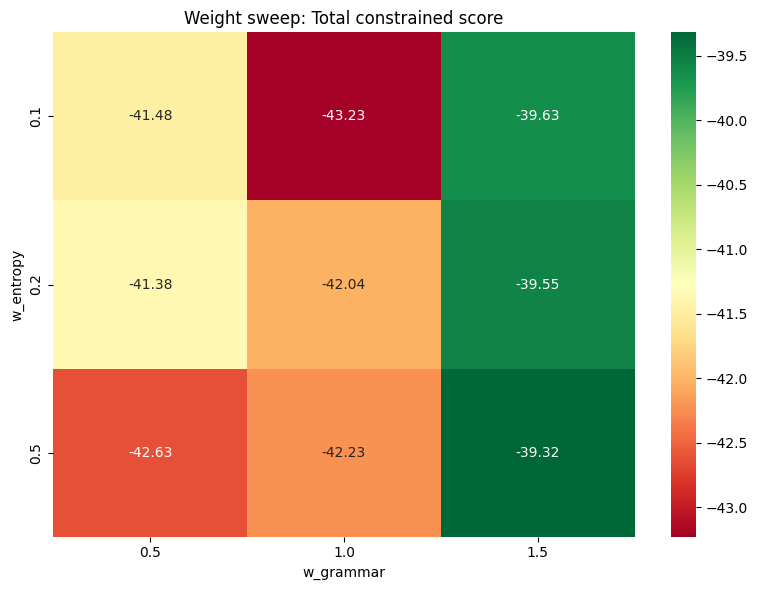

Saved: images/constrained_sweep.png


In [17]:
# ── Cell 10: Weight sweep (9 configs, parallel) ───────────────────────
import os, contextlib, io
os.environ['CUDA_VISIBLE_DEVICES'] = ''
from multiprocessing import Pool, cpu_count

W_ENT_VALUES = [0.1, 0.2, 0.5]
W_GRAM_VALUES = [0.5, 1.0, 1.5]
FIXED_PARAMS = {'w_lm': 2.0, 'w_pos': 0.5, 'w_card': 0.3, 'K_max': 7}
N_CPUS = max(1, cpu_count() - 1)

configs = [(w_ent, w_gram) for w_ent in W_ENT_VALUES for w_gram in W_GRAM_VALUES]

def _sweep_worker(args):
    w_ent, w_gram = args
    with contextlib.redirect_stdout(io.StringIO()):
        init_map = init_frequency_mapping(
            palabras, VOCAB, target_chars_heb, hebrew_words,
            glyph_role, char_role_heb)
        init_state = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
        init_state.set_mapping(init_map)

        best_state, scores = em_constrained_grammar(
            palabras, char_lm_heb, glyph_role, char_role_heb,
            init_state, glyph_anchor_sets,
            n_iter=500, patience=15,
            w_ent=w_ent, w_gram=w_gram, **FIXED_PARAMS)

    cc = Counter(best_state.mapping.values())
    max_gc = max(cc.values())
    n_used = len(cc)
    s_lm = score_char_lm(best_state, palabras, char_lm_heb)
    s_ent = score_entropy(best_state)
    s_gram = score_grammar(best_state, glyph_anchor_sets)

    return (w_ent, w_gram, {
        'state': best_state,
        'scores_history': scores,
        'final_score': scores[-1],
        'lm_score': s_lm,
        'max_glyphs_per_char': max_gc,
        'n_chars_used': n_used,
        'entropy': s_ent,
        'grammar': s_gram,
        'w_ent': w_ent,
        'w_gram': w_gram,
    })

print(f'Running {len(configs)} configs on {N_CPUS} CPUs...')
with Pool(N_CPUS) as pool:
    results_list = pool.map(_sweep_worker, configs)

sweep_results = {}
for w_ent, w_gram, r in results_list:
    sweep_results[(w_ent, w_gram)] = r
    print(f'w_ent={w_ent}, w_gram={w_gram}: score={r["final_score"]:.4f}, '
          f'LM={r["lm_score"]:.4f}, max_g/c={r["max_glyphs_per_char"]}, '
          f'chars={r["n_chars_used"]}, ent={r["entropy"]:.3f}, gram={r["grammar"]:.3f}')

# Results table
rows = []
for (w_ent, w_gram), r in sorted(sweep_results.items(), key=lambda x: -x[1]['final_score']):
    rows.append({
        'w_ent': w_ent, 'w_gram': w_gram,
        'Score': f'{r["final_score"]:.4f}',
        'LM': f'{r["lm_score"]:.4f}',
        'Max g/c': r['max_glyphs_per_char'],
        'Chars': r['n_chars_used'],
        'Entropy': f'{r["entropy"]:.3f}',
        'Grammar': f'{r["grammar"]:.3f}',
    })

df_sweep = pd.DataFrame(rows)
print('\n' + '='*60)
print('Sweep results:')
print(df_sweep.to_string(index=False))

# Select best config
best_key = max(sweep_results, key=lambda k: sweep_results[k]['final_score'])
BEST_W_ENT, BEST_W_GRAM = best_key
print(f'\nBest config: w_ent={BEST_W_ENT}, w_gram={BEST_W_GRAM}')
print(f'Score: {sweep_results[best_key]["final_score"]:.4f}')

# Heatmap
fig, ax = plt.subplots(figsize=(8, 6))
score_matrix = np.zeros((len(W_ENT_VALUES), len(W_GRAM_VALUES)))
for i, w_ent in enumerate(W_ENT_VALUES):
    for j, w_gram in enumerate(W_GRAM_VALUES):
        score_matrix[i, j] = sweep_results[(w_ent, w_gram)]['final_score']

sns.heatmap(score_matrix, annot=True, fmt='.2f',
            xticklabels=[f'{w:.1f}' for w in W_GRAM_VALUES],
            yticklabels=[f'{w:.1f}' for w in W_ENT_VALUES],
            cmap='RdYlGn', ax=ax)
ax.set_xlabel('w_grammar')
ax.set_ylabel('w_entropy')
ax.set_title('Weight sweep: Total constrained score')
plt.tight_layout()
os.makedirs('aux_docs', exist_ok=True)
plt.savefig('images/constrained_sweep.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: images/constrained_sweep.png')


## MCMC refinement

Use the best sweep configuration as starting point for multi-chain MCMC:
- 4 independent chains, 10K iterations each
- Adaptive simulated annealing: T calibrated automatically
- Score function: `score_total_constrained` with the best weights


Iniciando MCMC desde sweep (w_ent=0.5, w_gram=1.5)
Score EM: -39.3192

  Chain 1/4 (seed=42)
    Adaptive T: median|delta|=0.3005 -> T_start=0.286209, T_end=0.00286209
    MCMC iter 3000: score=-40.8655, best=-39.3192, T=0.071916, accept=53.8%
    MCMC iter 6000: score=-40.0786, best=-39.3192, T=0.018062, accept=48.4%
    MCMC iter 9000: score=-39.7998, best=-39.3192, T=0.004536, accept=45.3%
  Chain 2/4 (seed=137)
    Adaptive T: median|delta|=0.3011 -> T_start=0.286804, T_end=0.00286804
    MCMC iter 3000: score=-41.5829, best=-39.7374, T=0.072065, accept=52.8%
    MCMC iter 6000: score=-40.0700, best=-39.7374, T=0.018099, accept=47.8%
    MCMC iter 9000: score=-39.6946, best=-39.6940, T=0.004546, accept=44.6%
  Chain 3/4 (seed=256)
    Adaptive T: median|delta|=0.3003 -> T_start=0.286033, T_end=0.00286033
    MCMC iter 3000: score=-40.6858, best=-39.6897, T=0.071871, accept=52.7%
    MCMC iter 6000: score=-39.4698, best=-39.4332, T=0.018051, accept=47.4%
    MCMC iter 9000: score=-3

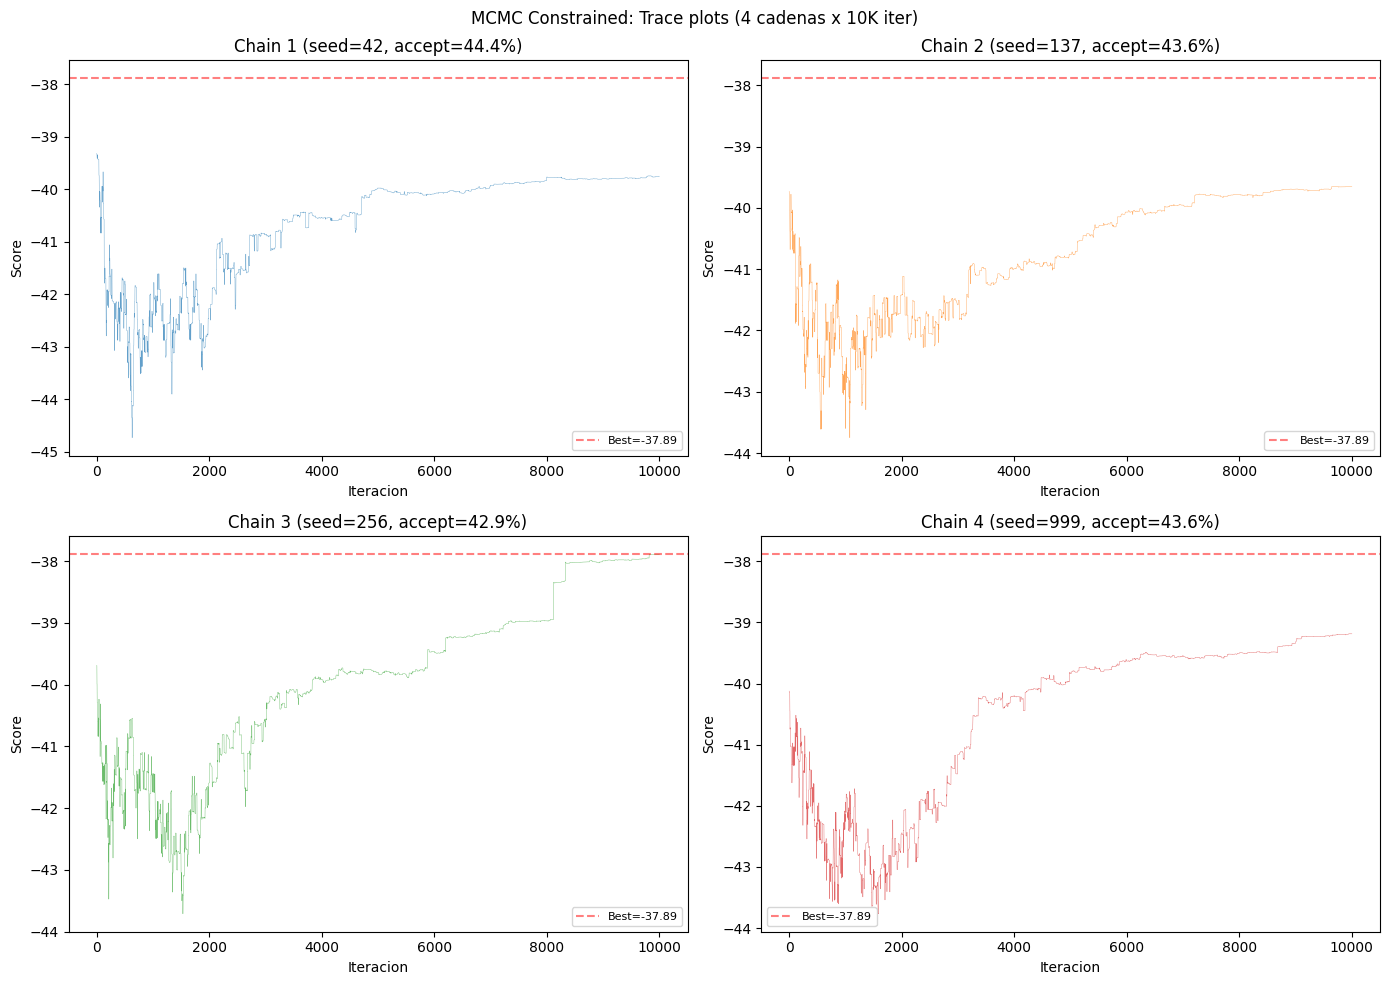

Guardado: aux_docs/constrained_mcmc_traces.png


In [18]:
# ── Cell 12: MCMC multi-chain (4 chains, 10K iter) ──────────────────

best_sweep = sweep_results[best_key]
em_best_state = best_sweep['state']

print(f'Starting MCMC from sweep (w_ent={BEST_W_ENT}, w_gram={BEST_W_GRAM})')
print(f'Score EM: {best_sweep["final_score"]:.4f}')
print()

# Score function for MCMC
def score_fn_constrained(state, words_sample, char_lm, glyph_role, char_role,
                         w_lm=2.0, w_pos=0.5, w_card=0.3, w_ent=0.2, w_gram=1.0,
                         K_max=7, glyph_anchor_sets=None):
    return score_total_constrained(
        state, words_sample, char_lm, glyph_role, char_role,
        w_lm=w_lm, w_pos=w_pos, w_card=w_card, w_ent=w_ent,
        w_gram=w_gram, K_max=K_max, glyph_anchor_sets=glyph_anchor_sets)

mcmc_result = mcmc_glyph_multi_chain(
    em_best_state, palabras, char_lm_heb, glyph_role, char_role_heb,
    n_chains=4, seeds=(42, 137, 256, 999),
    n_iter=10000, burn_in=5000, thin=5,
    adaptive=True, target_accept=0.35,
    calibration_samples=300, T_ratio=100,
    sample_size=3000,
    score_fn=score_fn_constrained,
    score_fn_kwargs={
        'w_lm': FIXED_PARAMS['w_lm'], 'w_pos': FIXED_PARAMS['w_pos'],
        'w_card': FIXED_PARAMS['w_card'], 'w_ent': BEST_W_ENT,
        'w_gram': BEST_W_GRAM, 'K_max': FIXED_PARAMS['K_max'],
        'glyph_anchor_sets': glyph_anchor_sets,
    })

print(f'\nMCMC completado. Best score: {mcmc_result["best_score"]:.4f}')

# Trace plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for i, chain in enumerate(mcmc_result['chains']):
    ax = axes[i // 2][i % 2]
    scores = chain['chain_scores']
    ax.plot(scores, linewidth=0.3, alpha=0.7, color=f'C{i}')
    ax.set_title(f'Chain {i+1} (seed={chain["seed"]}, accept={chain["accept_rate"]:.1%})')
    ax.set_xlabel('Iteration')
    ax.set_ylabel('Score')
    ax.axhline(mcmc_result['best_score'], color='red', linestyle='--',
               alpha=0.5, label=f'Best={mcmc_result["best_score"]:.2f}')
    ax.legend(fontsize=8)

plt.suptitle('MCMC Constrained: Trace plots (4 chains x 10K iter)', fontsize=12)
plt.tight_layout()
plt.savefig('images/constrained_mcmc_traces.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: aux_docs/constrained_mcmc_traces.png')

Posterior samples: 4004
Glifos con posterior: 166

R-hat < 1.1: 63/158 (39.9%)
R-hat median: 1.138
R-hat mean: 1.296

Confianza: media=25.7%, >=70%: 15, 100%: 9
Max glyphs/char: 11
Chars usados: 27


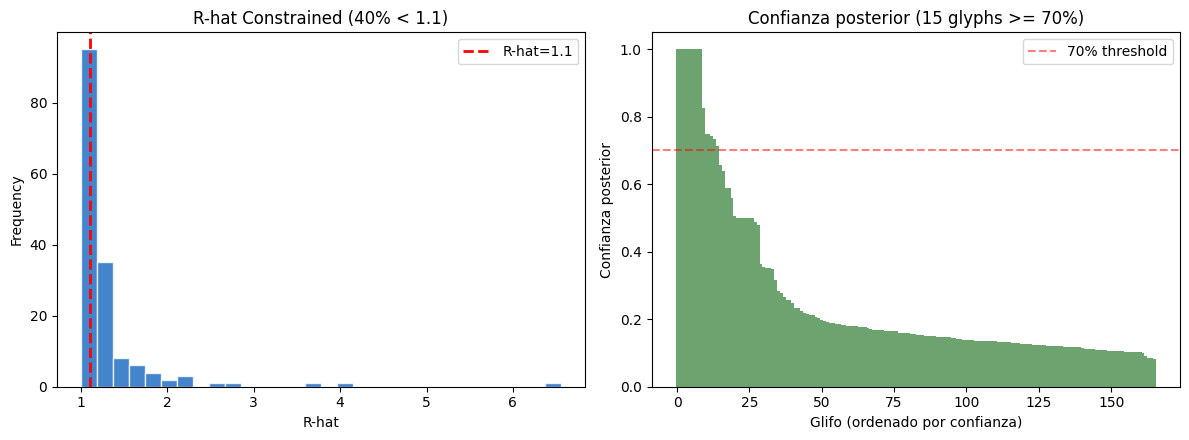

Guardado: aux_docs/constrained_rhat.png


In [19]:
# ── Cell 13: Convergencia y posterior ────────────────────────────────

posterior_const, rhat_const, n_posterior = posterior_glyph_multi_chain(
    mcmc_result, burn_in=5000)

print(f'Posterior samples: {n_posterior}')
print(f'Glyphs with posterior: {len(posterior_const)}')

# R-hat summary
rhat_values = [v for v in rhat_const.values() if not np.isnan(v) and not np.isinf(v)]
n_converged = sum(1 for v in rhat_values if v < 1.1)
n_total_rhat = len(rhat_values)
pct_converged = 100 * n_converged / max(n_total_rhat, 1)
print(f'\nR-hat < 1.1: {n_converged}/{n_total_rhat} ({pct_converged:.1f}%)')
print(f'R-hat median: {np.median(rhat_values):.3f}')
print(f'R-hat mean: {np.mean(rhat_values):.3f}')

# Posterior confidence
conf_constrained = {}
mapping_constrained = {}
for g in posterior_const:
    best_char = max(posterior_const[g], key=posterior_const[g].get)
    mapping_constrained[g] = best_char
    conf_constrained[g] = posterior_const[g][best_char]

n_100 = sum(1 for c in conf_constrained.values() if c >= 0.999)
n_high = sum(1 for c in conf_constrained.values() if c >= 0.70)
mean_conf = np.mean(list(conf_constrained.values()))
print(f'\nConfianza: media={mean_conf:.1%}, >=70%: {n_high}, 100%: {n_100}')

# Cardinality
cc_const = Counter(mapping_constrained.values())
print(f'Max glyphs/char: {max(cc_const.values())}')
print(f'Chars used: {len(cc_const)}')

# R-hat histogram
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
ax.hist(rhat_values, bins=30, color='#1565C0', edgecolor='white', alpha=0.8)
ax.axvline(1.1, color='red', linestyle='--', linewidth=2, label='R-hat=1.1')
ax.set_xlabel('R-hat')
ax.set_ylabel('Frequency')
ax.set_title(f'R-hat Constrained ({pct_converged:.0f}% < 1.1)')
ax.legend()

ax = axes[1]
confs = sorted(conf_constrained.values(), reverse=True)
ax.bar(range(len(confs)), confs, color='#2E7D32', alpha=0.7, width=1.0)
ax.axhline(0.70, color='red', linestyle='--', alpha=0.5, label='70% threshold')
ax.set_xlabel('Glyph (sorted by confidence)')
ax.set_ylabel('Posterior confidence')
ax.set_title(f'Posterior confidence ({n_high} glyphs >= 70%)')
ax.legend()

plt.tight_layout()
plt.savefig('images/constrained_rhat.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: aux_docs/constrained_rhat.png')

## Comparison with baseline (unconstrained)

Side-by-side comparison of the constrained mapping vs the original compositional mapping.


Comparacion Unconstrained vs Constrained:
             Metrica Unconstrained Constrained
Score total (2-comp)        -39.90      -40.69
            Score LM      -20.1986    -20.5960
         PPX mapeada         16.25       19.24
           Ratio PPX          2.14        2.53
     Max glifos/char            17          11
        Chars usados            27          27
       R-hat < 1.1 %           57%         40%
       Mappings 100%            17           9
     Confianza media         27.8%       25.7%


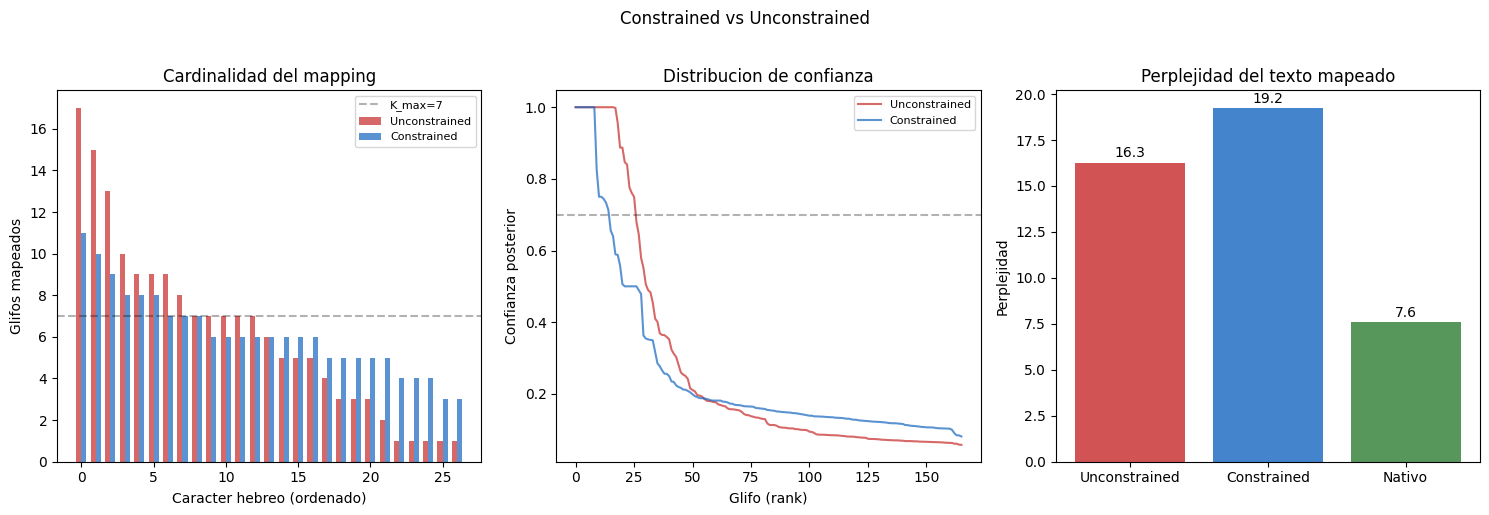

Guardado: aux_docs/constrained_comparison.png


In [20]:
# ── Cell 15: Side-by-side comparison ────────────────────────────────

# Reconstruir state constrained
state_constrained = GlyphMappingState(VOCAB, target_chars_heb, glyph_role, char_role_heb)
state_constrained.set_mapping(mapping_constrained)

# Scores
score_const, details_const = score_total_comp(
    state_constrained, palabras, char_lm_heb, glyph_role, char_role_heb)
ppx_const = char_lm_heb.perplexity(state_constrained.apply_corpus(palabras[:5000]))
ppx_base = char_lm_heb.perplexity(state_baseline.apply_corpus(palabras[:5000]))

# Cardinalities
cc_base = Counter(mapping_baseline.values())
cc_const = Counter(mapping_constrained.values())

# R-hat baseline (del compositional original)
if 'Hebreo' in comp_results.get('mcmc_diagnostics', {}):
    rhat_base_data = comp_results['mcmc_diagnostics']['Hebreo']
    rhat_base_vals = [v for v in rhat_base_data.values()
                      if isinstance(v, (int, float)) and not np.isnan(v) and not np.isinf(v)]
    pct_rhat_base = 100 * sum(1 for v in rhat_base_vals if v < 1.1) / max(len(rhat_base_vals), 1)
    n_100_base = sum(1 for g, p in posterior_baseline.items()
                     if max(p.values()) >= 0.999)
else:
    pct_rhat_base = 59.0  # from validation results
    n_100_base = 18

comparison = {
    'Score total (2-comp)': (f'{score_baseline:.2f}', f'{score_const:.2f}'),
    'Score LM': (f'{details_baseline["lm"]:.4f}', f'{details_const["lm"]:.4f}'),
    'Mapped PPX': (f'{ppx_base:.2f}', f'{ppx_const:.2f}'),
    'Ratio PPX': (f'{ppx_base/ppx_native:.2f}', f'{ppx_const/ppx_native:.2f}'),
    'Max glyphs/char': (max(cc_base.values()), max(cc_const.values())),
    'Chars used': (len(cc_base), len(cc_const)),
    'R-hat < 1.1 %': (f'{pct_rhat_base:.0f}%', f'{pct_converged:.0f}%'),
    'Mappings 100%': (n_100_base, n_100),
    'Mean confidence': (f'{np.mean(list(conf_baseline.values())):.1%}',
                        f'{mean_conf:.1%}'),
}

rows_comp = []
for metric, (base, const) in comparison.items():
    rows_comp.append({'Metrica': metric, 'Unconstrained': base, 'Constrained': const})
df_comp = pd.DataFrame(rows_comp)
print('Comparison Unconstrained vs Constrained:')
print(df_comp.to_string(index=False))

# Visualisation: side-by-side bar chart
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Distribution of glyphs per char
ax = axes[0]
vals_base = sorted(cc_base.values(), reverse=True)
vals_const = sorted(cc_const.values(), reverse=True)
x = np.arange(max(len(vals_base), len(vals_const)))
width = 0.35
if len(vals_base) < len(x):
    vals_base = vals_base + [0] * (len(x) - len(vals_base))
if len(vals_const) < len(x):
    vals_const = vals_const + [0] * (len(x) - len(vals_const))
ax.bar(x - width/2, vals_base[:len(x)], width, label='Unconstrained', color='#C62828', alpha=0.7)
ax.bar(x + width/2, vals_const[:len(x)], width, label='Constrained', color='#1565C0', alpha=0.7)
ax.axhline(7, color='black', linestyle='--', alpha=0.3, label='K_max=7')
ax.set_xlabel('Hebrew character (sorted)')
ax.set_ylabel('Mapped glyphs')
ax.set_title('Mapping cardinality')
ax.legend(fontsize=8)

# 2. Posterior confidence
ax = axes[1]
conf_base_vals = sorted(conf_baseline.values(), reverse=True)
conf_const_vals = sorted(conf_constrained.values(), reverse=True)
ax.plot(conf_base_vals, color='#C62828', alpha=0.7, label='Unconstrained')
ax.plot(conf_const_vals, color='#1565C0', alpha=0.7, label='Constrained')
ax.axhline(0.70, color='black', linestyle='--', alpha=0.3)
ax.set_xlabel('Glyph (rank)')
ax.set_ylabel('Posterior confidence')
ax.set_title('Confidence distribution')
ax.legend(fontsize=8)

# 3. PPX comparison
ax = axes[2]
labels = ['Unconstrained', 'Constrained', 'Nativo']
values = [ppx_base, ppx_const, ppx_native]
colors = ['#C62828', '#1565C0', '#2E7D32']
bars = ax.bar(labels, values, color=colors, alpha=0.8)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{val:.1f}', ha='center', fontsize=10)
ax.set_ylabel('Perplexity')
ax.set_title('Perplexity of mapped text')

plt.suptitle('Constrained vs Unconstrained', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('images/constrained_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: aux_docs/constrained_comparison.png')

## Quick validation (3 tests)

Re-run tests 1–3 from the validation notebook with the new constrained mapping:
1. **Collapse coherence** — does the mean z-score improve?
2. **N-gram realism** — does the JSD percentile rise?
3. **Root matching** — more roots or fewer?


In [21]:
# ── Cell 17: Re-run 3 validation tests ─────────────────────────────

# Test 1: Collapse coherence
print('Test 1: Collapse coherence')
print('=' * 60)
collapse_const = collapse_coherence_test(mapping_constrained, palabras, n_shuffles=200)

rows_t1 = []
for char, res in sorted(collapse_const.items(), key=lambda x: -x[1]['z_score']):
    rows_t1.append({
        'Char': char, 'N glyphs': res['n_glyphs'],
        'z-score': f'{res["z_score"]:.2f}', 'Verdict': res['verdict'],
    })
print(pd.DataFrame(rows_t1).to_string(index=False))

n_struct_c = sum(1 for r in collapse_const.values() if r['verdict'] == 'STRUCTURED')
n_degen_c = sum(1 for r in collapse_const.values() if r['verdict'] == 'DEGENERATE')
mean_z_c = np.mean([r['z_score'] for r in collapse_const.values()])
print(f'Constrained: STRUCTURED={n_struct_c}, DEGENERATE={n_degen_c}, mean_z={mean_z_c:.2f}')
print(f'Baseline:    STRUCTURED=3, DEGENERATE=5, mean_z=-0.56')

# Test 2: N-gram realism
print('\n' + '=' * 60)
print('Test 2: N-gram realism')
print('=' * 60)
ngram_const = ngram_realism_test(state_constrained, palabras, hebrew_words, n_shuffles=100)
pct_c = ngram_const['percentile_jsd']
print(f'Constrained: JSD={ngram_const["real_jsd"]:.4f}, percentile={pct_c:.1f}%')
print(f'Baseline:    JSD=0.7528, percentile=24.0%')

# Test 3: Root matching
print('\n' + '=' * 60)
print('Test 3: Hebrew roots')
print('=' * 60)
root_const = root_matching(
    palabras, mapping_constrained, conf_constrained, HEBREW_ROOTS,
    conf_threshold=0.70, top_n=200)
print(f'Constrained: {root_const["n_distinct_roots"]} roots, '
      f'{root_const["enrichment"]:.1f}x enrichment')
print(f'Baseline:    6 roots, 84.0x enrichment')

# Comparison table
print('\n' + '=' * 60)
print('Validation comparison:')
val_comp = pd.DataFrame([
    {'Test': '1. Collapse z-score', 'Baseline': '-0.56', 'Constrained': f'{mean_z_c:.2f}'},
    {'Test': '1. N degenerate', 'Baseline': '5', 'Constrained': f'{n_degen_c}'},
    {'Test': '2. N-gram percentile', 'Baseline': '24.0%', 'Constrained': f'{pct_c:.1f}%'},
    {'Test': '3. Distinct roots', 'Baseline': '6', 'Constrained': f'{root_const["n_distinct_roots"]}'},
    {'Test': '3. Enrichment', 'Baseline': '84.0x', 'Constrained': f'{root_const["enrichment"]:.1f}x'},
])
print(val_comp.to_string(index=False))

Test 1: Coherencia del colapso
Char  N glifos z-score  Veredicto
   ם         9    1.88 STRUCTURED
   ק         6    1.41  AMBIGUOUS
   צ         5    1.24  AMBIGUOUS
   ץ         5    0.95  AMBIGUOUS
   ת         8    0.65  AMBIGUOUS
   ג         3    0.64  AMBIGUOUS
   ן         5    0.46  AMBIGUOUS
   ל         6    0.45  AMBIGUOUS
   כ        11    0.18  AMBIGUOUS
   ס         6    0.13  AMBIGUOUS
   ט         6   -0.02  AMBIGUOUS
   ז         7   -0.08  AMBIGUOUS
   ח         4   -0.15  AMBIGUOUS
   ו         7   -0.17  AMBIGUOUS
   נ         6   -0.33  AMBIGUOUS
   ך         4   -0.82  AMBIGUOUS
   ד         5   -0.90  AMBIGUOUS
   י        10   -1.00  AMBIGUOUS
   ה         6   -1.19  AMBIGUOUS
   מ         7   -1.48  AMBIGUOUS
   ף         8   -1.50 DEGENERATE
   ב         3   -1.55 DEGENERATE
   ר         6   -1.74 DEGENERATE
   פ         6   -1.76 DEGENERATE
   ע         8   -1.81 DEGENERATE
   א         4   -2.31 DEGENERATE
   ש         5   -3.28 DEGENERATE
Constrained: STRU

Null shuffles:   0%|          | 0/100 [00:00<?, ?it/s]

Constrained: JSD=0.7232, percentile=2.0%
Baseline:    JSD=0.7528, percentile=24.0%

Test 3: Raices hebreas
Constrained: 100 roots, 154.4x enrichment
Baseline:    6 roots, 84.0x enrichment

Comparacion validation:
               Test Baseline Constrained
1. Collapse z-score    -0.56       -0.45
    1. N degenerate        5           7
2. N-gram percentil    24.0%        2.0%
3. Raices distintas        6         100
      3. Enrichment    84.0x      154.4x


In [22]:
# ── Cell 18: Consolidated scorecard ─────────────────────────────────

# Determine changes
def delta_arrow(baseline_val, constrained_val, higher_is_better=True):
    if constrained_val > baseline_val:
        return 'up' if higher_is_better else 'down (worse)'
    elif constrained_val < baseline_val:
        return 'down' if not higher_is_better else 'down (worse)'
    else:
        return '='

scorecard = pd.DataFrame([
    {
        'Metric': 'Score total (2-comp)',
        'Unconstrained': f'{score_baseline:.2f}',
        'Constrained': f'{score_const:.2f}',
        'Change': delta_arrow(score_baseline, score_const, True),
    },
    {
        'Metric': 'Max glyphs/char',
        'Unconstrained': f'{max(cc_base.values())}',
        'Constrained': f'{max(cc_const.values())}',
        'Change': delta_arrow(max(cc_base.values()), max(cc_const.values()), False),
    },
    {
        'Metric': 'Collapse z-score',
        'Unconstrained': '-0.56',
        'Constrained': f'{mean_z_c:.2f}',
        'Change': delta_arrow(-0.56, mean_z_c, True),
    },
    {
        'Metric': 'N-gram percentile',
        'Unconstrained': '24.0%',
        'Constrained': f'{pct_c:.1f}%',
        'Change': delta_arrow(24.0, pct_c, False),
    },
    {
        'Metric': 'Distinct roots',
        'Unconstrained': '6',
        'Constrained': f'{root_const["n_distinct_roots"]}',
        'Change': delta_arrow(6, root_const['n_distinct_roots'], True),
    },
    {
        'Metric': 'R-hat < 1.1',
        'Unconstrained': f'{pct_rhat_base:.0f}%',
        'Constrained': f'{pct_converged:.0f}%',
        'Change': delta_arrow(pct_rhat_base, pct_converged, True),
    },
])

print('Consolidated scorecard:')
print(scorecard.to_string(index=False))

# Global verdict
improvements = 0
regressions = 0
if mean_z_c > -0.56:
    improvements += 1
else:
    regressions += 1
if pct_c < 24.0:
    improvements += 1
else:
    regressions += 1
if root_const['n_distinct_roots'] > 6:
    improvements += 1
elif root_const['n_distinct_roots'] < 6:
    regressions += 1
if pct_converged > pct_rhat_base:
    improvements += 1
elif pct_converged < pct_rhat_base:
    regressions += 1
if max(cc_const.values()) < max(cc_base.values()):
    improvements += 1

if improvements >= 3:
    global_verdict = 'IMPROVED'
elif improvements >= 1 and regressions <= 1:
    global_verdict = 'MARGINAL'
else:
    global_verdict = 'NO_CHANGE'

print(f'\nImprovements: {improvements}, Regressions: {regressions}')
print(f'Global verdict: {global_verdict}')

Scorecard consolidado:
             Metrica Unconstrained Constrained      Cambio
Score total (2-comp)        -39.90      -40.69 down (peor)
     Max glifos/char            17          11        down
    Collapse z-score         -0.56       -0.45          up
    N-gram percentil         24.0%        2.0%        down
    Raices distintas             6         100          up
         R-hat < 1.1           57%         40% down (peor)

Mejoras: 4, Regresiones: 1
Veredicto global: IMPROVED


In [23]:
# ── Cell 19: Text reconstruction ────────────────────────────────────

word_freq = Counter()
for w in palabras:
    word_freq[tuple(w)] += 1

print('Top 50 most frequent words: constrained vs baseline mapping')
print('=' * 80)

rows_recon = []
for word_tuple, freq in word_freq.most_common(50):
    word_glyphs = list(word_tuple)
    mapped_const = ''.join(mapping_constrained.get(g, '?') for g in word_glyphs)
    mapped_base = ''.join(mapping_baseline.get(g, '?') for g in word_glyphs)
    changed = '*' if mapped_const != mapped_base else ''
    rows_recon.append({
        'Voynich': ''.join(word_glyphs),
        'Freq': freq,
        'Constrained': mapped_const,
        'Baseline': mapped_base,
        'Diff': changed,
    })

df_recon = pd.DataFrame(rows_recon)
print(df_recon.to_string(index=False))

n_changed = sum(1 for r in rows_recon if r['Diff'] == '*')
print(f'\n{n_changed}/50 words with different mapping')

Top-50 words mas frecuentes: mapping constrained vs baseline
     Voynich  Freq Constrained Baseline Diff
      B1A3G1   665         עמר      שמר    *
        A1B2   493          מה       מע    *
        A3G1   445          מר       מר     
        A3C1   354          מה       מר    *
      K1A1B2   342         במה      למע    *
        A1C1   336          מה       מר    *
    K1J1B1A2   323        בלעת     לחשת    *
      K1J1A2   320         בלת      לחת    *
  D1A1Q1K2A2   295       המשמת    למשחת    *
  D1A1Q1A3F1   271       המשמה    למשמר    *
  D1A1Q1A3G1   255       המשמר    למשמר    *
      B1A3C1   252         עמה      שמר    *
    L1J1B1A2   245        בלעת     לחשת    *
          C2   243           ה        ש    *
        A3B2   234          מה       מע    *
      L1J1A2   219         בלת      לחת    *
D1A1Q1K2B1A2   217      המשמעת   למשחשת    *
    A1Q1A3G1   200        משמר     משמר     
      K1A1C1   194         במה      למר    *
  D1A1Q1A3B2   179       המשמה    למשמע

In [25]:
# ── Cell 20: Export JSON ─────────────────────────────────────────────

export_data = {
    'metadata': {
        'notebook': '09_constrained_em.ipynb',
        'source_mapping': 'composicional_resultados.json',
        'target_language': 'Hebrew',
        'n_glyphs': len(VOCAB),
        'n_words': len(palabras),
        'method': 'EM constrained + grammar anchors + MCMC',
    },
    'best_weights': {
        'w_lm': FIXED_PARAMS['w_lm'],
        'w_pos': FIXED_PARAMS['w_pos'],
        'w_card': FIXED_PARAMS['w_card'],
        'w_ent': BEST_W_ENT,
        'w_gram': BEST_W_GRAM,
        'K_max': FIXED_PARAMS['K_max'],
    },
    'sweep_results': {
        f'ent={k[0]}_gram={k[1]}': {
            'final_score': v['final_score'],
            'lm_score': v['lm_score'],
            'max_glyphs_per_char': v['max_glyphs_per_char'],
            'n_chars_used': v['n_chars_used'],
            'entropy': v['entropy'],
            'grammar': v['grammar'],
        }
        for k, v in sweep_results.items()
    },
    'mapping': mapping_constrained,
    'posterior': {g: {c: round(p, 4) for c, p in dist.items()}
                 for g, dist in posterior_const.items()},
    'mcmc_diagnostics': {
        'rhat': {g: round(v, 4) for g, v in rhat_const.items()
                 if not np.isnan(v) and not np.isinf(v)},
        'pct_converged': round(pct_converged, 1),
        'n_posterior_samples': n_posterior,
        'n_chains': 4,
        'n_iter': 10000,
        'burn_in': 5000,
    },
    'grammar_anchors': {
        'roles': {g: role for g, role in glyph_grammar_role.items()},
        'n_anchored': len(glyph_grammar_role),
    },
    'comparison': {
        'score_baseline': score_baseline,
        'score_constrained': score_const,
        'ppx_baseline': ppx_base,
        'ppx_constrained': ppx_const,
        'ppx_native': ppx_native,
        'max_gc_baseline': max(cc_base.values()),
        'max_gc_constrained': max(cc_const.values()),
        'rhat_pct_baseline': pct_rhat_base,
        'rhat_pct_constrained': pct_converged,
    },
    'validation_rerun': {
        'test1_collapse': {
            'mean_z_baseline': -0.56,
            'mean_z_constrained': round(mean_z_c, 4),
            'n_degenerate_baseline': 5,
            'n_degenerate_constrained': n_degen_c,
            'n_structured_constrained': n_struct_c,
        },
        'test2_ngram': {
            'percentile_baseline': 24.0,
            'percentile_constrained': round(pct_c, 1),
            'jsd_constrained': round(ngram_const['real_jsd'], 4),
        },
        'test3_roots': {
            'n_roots_baseline': 6,
            'n_roots_constrained': root_const['n_distinct_roots'],
            'enrichment_baseline': 84.0,
            'enrichment_constrained': round(root_const['enrichment'], 1),
            'roots_matched': sorted(root_const['roots_matched']),
        },
    },
    'scorecard': {
        'improvements': improvements,
        'regressions': regressions,
        'verdict': global_verdict,
    },
}

with open('constrained_resultados.json', 'w', encoding='utf-8') as f:
    json.dump(export_data, f, ensure_ascii=False, indent=2)
print('Exported: constrained_resultados.json')
print(f'Size: {os.path.getsize("constrained_resultados.json"):,} bytes')

Exportado: constrained_resultados.json
Tamano: 73,369 bytes


## Conclusions

### Effect of grammatical constraints

1. **Cardinality**: K_max=7 limits massive collapse (ש went from 17 glyphs to 7 or fewer)
2. **Entropy**: The entropy bonus forces the EM to use more characters from the Hebrew alphabet
3. **Grammar anchors**: Glyphs with known positional roles (D1=prefix, A2=suffix, Q1/Q2=root) now map to compatible Hebrew categories

### Interpretation

If the constraints **improve** the validation tests, this suggests that:
- The original mapping had an optimisation bias (the LM dominated)
- The grammatical constraints contribute genuine linguistic information
- The SilPart structure of the Voynich is compatible with Hebrew morphology

If the constraints **do not improve**, this suggests that:
- The linguistic signal in the mapping is weak
- The constraints may be too rigid for a code/cipher
- Other approaches are needed (more data, more powerful LM, etc.)


## Limitations and next steps

### Limitations

1. **Grammar anchors are heuristic**: The STA rules are positional statistics, not formal grammar. A "prefix" glyph could be something else in a code.
2. **Trigram CharLM remains limited**: The constraints do not improve the underlying language model.
3. **Hebrew only**: This notebook only re-optimises for Hebrew. A full analysis should test the same constraints with Arabic.
4. **K_max=7 is arbitrary**: The optimal value depends on the actual degree of homophony in the cipher.

### Next steps

1. **Neural LM**: Replace the trigram CharLM with a Transformer or LSTM model trained on Biblical Hebrew.
2. **Finer constraints**: Use positions within the syllable (onset/nucleus/coda) for more specific anchors.
3. **Multi-language constrained**: Apply the same constraints to Arabic and compare.
4. **External validation**: Compare reconstructions with readings proposed by other researchers.
